In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
# import random
from torch import nn, optim
from torch.optim.lr_scheduler import StepLR, LinearLR, SequentialLR
from functions import *

In [2]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE,"/", torch.cuda.get_device_name() if DEVICE=="cuda" else "-")

cuda / NVIDIA GeForce RTX 5060


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4377, 0.4438, 0.4728), (0.1980, 0.2010, 0.1970)) # SVHN 평균/표준편차
])

train_set = torchvision.datasets.SVHN(root='./data', split='train', download=True, transform=transform)
extra_set = torchvision.datasets.SVHN(root='./data', split='extra', download=True, transform=transform)
test_set = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=transform)

train_set, val_set = torch.utils.data.random_split(train_set, [int(len(train_set)*0.8), len(train_set)-int(len(train_set)*0.8)])


In [4]:
# hyperparameters

code = "SVHN_CNN"
BATCH_SIZE = 128

LR = 3 * 1e-4
EPOCH = 30
new_model_train = True

initial_lr = LR
warmup_epochs = 3

base_model_path = "C:\\py\\Pytorch\\실습\\models"

In [5]:
print(f"n_of_train_samples: {len(train_set)}")
print(f"n_of_val_samples: {len(val_set)}")
print(f"n_of_extra_samples: {len(extra_set)}")
print(f"n_of_test_samples: {len(test_set)}")

train_DL = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_DL = torch.utils.data.DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=True)
val_DL = torch.utils.data.DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=True)  

n_of_train_samples: 58605
n_of_val_samples: 14652
n_of_extra_samples: 531131
n_of_test_samples: 26032


In [6]:
class JMNET(nn.Module):

    def __init__(self):
        super().__init__()

        self.CNNblock1 = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1),
                                       nn.ReLU(),
                                       nn.Conv2d(8, 16, 3, padding=1),
                                       nn.ReLU(),
                                       nn.MaxPool2d(2)
        )

        self.CNNblock2 = nn.Sequential(nn.Conv2d(16, 32, 3, padding=1),
                                       nn.ReLU(),
                                       nn.Conv2d(32, 64, 3, padding=1),
                                       nn.ReLU(),
                                       nn.MaxPool2d(2)
        )
        self.CNNblock3 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1),
                                       nn.ReLU(),
                                       nn.Conv2d(128, 256, 3, padding=1),
                                       nn.ReLU(),
                                       nn.MaxPool2d(2)
        )
        
        self.featue_extractor = nn.Sequential(
            self.CNNblock1,
            self.CNNblock2,
            self.CNNblock3
        )
        self.classifier = nn.Sequential(nn.Flatten(),
                                        nn.Linear(256*4*4, 512),
                                        nn.ReLU(),
                                        nn.Dropout(p = 0.3),
                                        nn.Linear(512,128),
                                        nn.ReLU(),
                                        nn.Dropout(p = 0.2),
                                        nn.Linear(128,10)

        )


    def forward(self, x):
        x = self.featue_extractor(x)
        x = self.classifier(x)
        return x


In [7]:
model = JMNET().to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr = initial_lr)
scheduler_warmup = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_epochs)
scheduler_main = StepLR(optimizer, step_size=10, gamma=0.5)
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_main], milestones = [warmup_epochs])
criterion = nn.CrossEntropyLoss()

In [10]:
from torchinfo import summary
summary(model, input_size=(1,3,32,32), device='cpu')

Layer (type:depth-idx)                   Output Shape              Param #
JMNET                                    [1, 10]                   --
├─Sequential: 1-1                        [1, 256, 4, 4]            --
│    └─Sequential: 2-1                   [1, 16, 16, 16]           --
│    │    └─Conv2d: 3-1                  [1, 8, 32, 32]            224
│    │    └─ReLU: 3-2                    [1, 8, 32, 32]            --
│    │    └─Conv2d: 3-3                  [1, 16, 32, 32]           1,168
│    │    └─ReLU: 3-4                    [1, 16, 32, 32]           --
│    │    └─MaxPool2d: 3-5               [1, 16, 16, 16]           --
│    └─Sequential: 2-2                   [1, 64, 8, 8]             --
│    │    └─Conv2d: 3-6                  [1, 32, 16, 16]           4,640
│    │    └─ReLU: 3-7                    [1, 32, 16, 16]           --
│    │    └─Conv2d: 3-8                  [1, 64, 16, 16]           18,496
│    │    └─ReLU: 3-9                    [1, 64, 16, 16]           --
│   

Model saved at epoch 1 with validation loss 2.238 in C:\py\Pytorch\실습\models\SVHN_CNN_20260202_1.pt
EPOCH: 1 /LR: 0.000120 / EPOCH Duration: 10.91 sec / CUDA Memory Usage: 59.8 MB
train loss: 2.249 / Validation loss: 2.238 / Validation accuracy: 0.188


Model saved at epoch 2 with validation loss 1.035 in C:\py\Pytorch\실습\models\SVHN_CNN_20260202_2.pt
EPOCH: 2 /LR: 0.000210 / EPOCH Duration: 10.51 sec / CUDA Memory Usage: 59.8 MB
train loss: 1.698 / Validation loss: 1.035 / Validation accuracy: 0.665


Model saved at epoch 3 with validation loss 0.593 in C:\py\Pytorch\실습\models\SVHN_CNN_20260202_3.pt
EPOCH: 3 /LR: 0.000300 / EPOCH Duration: 10.39 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.821 / Validation loss: 0.593 / Validation accuracy: 0.812


Model saved at epoch 4 with validation loss 0.443 in C:\py\Pytorch\실습\models\SVHN_CNN_20260202_4.pt
EPOCH: 4 /LR: 0.000300 / EPOCH Duration: 10.02 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.541 / Validation loss: 0.443 / Validation accuracy: 0.863


Model saved at epoch 5 with validation loss 0.367 in C:\py\Pytorch\실습\models\SVHN_CNN_20260202_5.pt
EPOCH: 5 /LR: 0.000300 / EPOCH Duration: 9.96 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.414 / Validation loss: 0.367 / Validation accuracy: 0.887


...

EPOCH: 26 /LR: 0.000075 / EPOCH Duration: 10.03 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.009 / Validation loss: 0.557 / Validation accuracy: 0.928


EPOCH: 27 /LR: 0.000075 / EPOCH Duration: 9.75 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.008 / Validation loss: 0.578 / Validation accuracy: 0.929


EPOCH: 28 /LR: 0.000075 / EPOCH Duration: 9.98 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.007 / Validation loss: 0.569 / Validation accuracy: 0.929


EPOCH: 29 /LR: 0.000075 / EPOCH Duration: 9.67 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.008 / Validation loss: 0.583 / Validation accuracy: 0.929


EPOCH: 30 /LR: 0.000075 / EPOCH Duration: 10.05 sec / CUDA Memory Usage: 59.8 MB
train loss: 0.006 / Validation loss: 0.647 / Validation accuracy: 0.928
Total Training Time: 297.17 sec


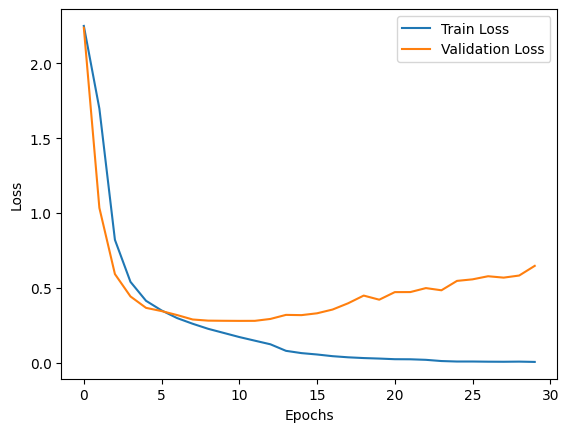

In [15]:
if new_model_train:
    loss_history = Train(model, EPOCH, DEVICE, train_DL, val_DL, criterion, optimizer, base_model_path, code, scheduler=scheduler)
    plot_loss(loss_history)
    

In [8]:
best_model_path = "C:\\py\\Pytorch\\실습\\models\\Sim_20260128_10.pt"
best_model = JMNET().to(DEVICE)
model_checkpoint = torch.load(best_model_path, map_location=DEVICE)
best_model.load_state_dict(model_checkpoint["model_state_dict"])

<All keys matched successfully>

In [9]:
model_test_acc = Test(model, DEVICE, test_DL, criterion)

best_test_acc = Test(best_model, DEVICE, test_DL, criterion)

print()
print(f"Model Test Accuracy: {round(model_test_acc,3)}")
print(f"Best Model Test Accuracy: {round(best_test_acc,3)}")

Test Loss: 2.29442 / Test Accuracy: 0.19587
Correct 5099 out of 26032


Test Loss: 0.2634 / Test Accuracy: 0.92655
Correct 24120 out of 26032

Model Test Accuracy: 0.196
Best Model Test Accuracy: 0.927


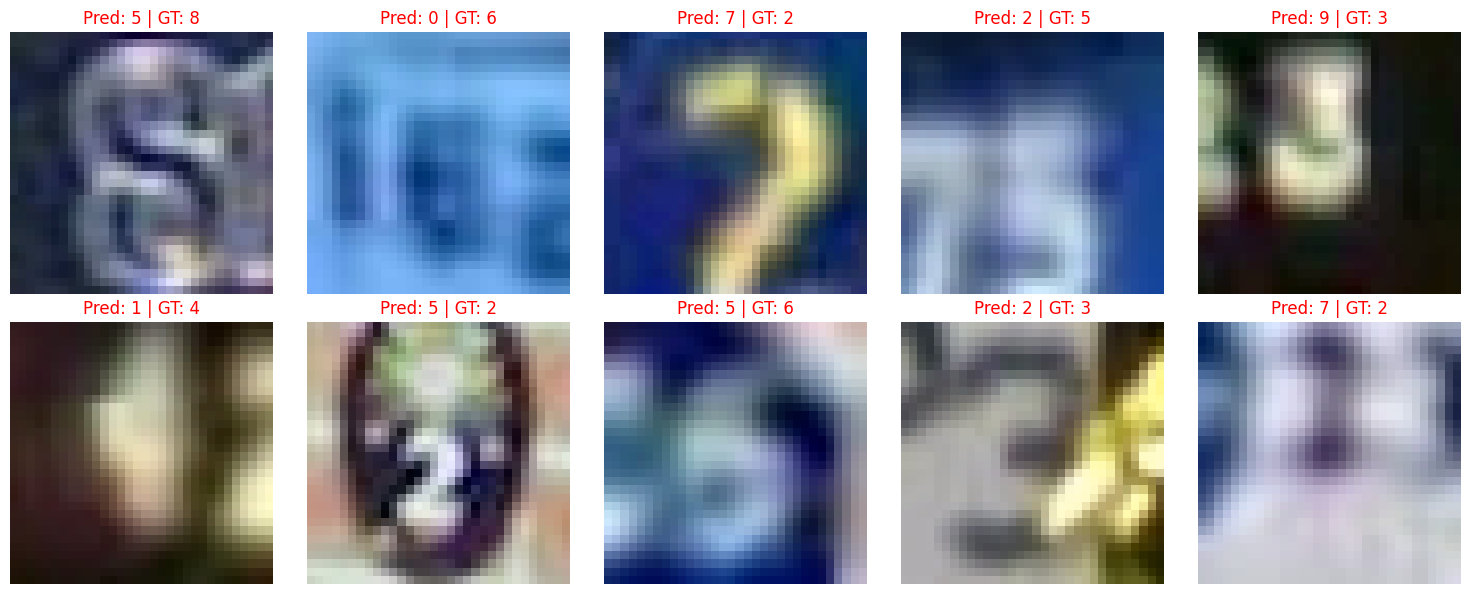

In [10]:
visualize_wrong(best_model, test_DL, DEVICE, n_of_show = 10)

In [11]:
for name, module in model.named_modules(): print(name)


CNNblock1
CNNblock1.0
CNNblock1.1
CNNblock1.2
CNNblock1.3
CNNblock1.4
CNNblock2
CNNblock2.0
CNNblock2.1
CNNblock2.2
CNNblock2.3
CNNblock2.4
CNNblock3
CNNblock3.0
CNNblock3.1
CNNblock3.2
CNNblock3.3
CNNblock3.4
featue_extractor
classifier
classifier.0
classifier.1
classifier.2
classifier.3
classifier.4
classifier.5
classifier.6
classifier.7


In [ ]:
target_layer_names = ["CNNblock1", "CNNblock2", "CNNblock3.2", "CNNblock3"]

img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((32,32)),
    transforms.Normalize((0.4377, 0.4438, 0.4728), (0.1980, 0.2010, 0.1970)) # SVHN 평균/표준편차
])

data_iter = iter(test_DL)
images, labels = next(data_iter)
single_image = images[0]




Layer: CNNblock1, Feature Map Shape: torch.Size([1, 16, 16, 16])
Layer: CNNblock2, Feature Map Shape: torch.Size([1, 64, 8, 8])
Layer: CNNblock3.2, Feature Map Shape: torch.Size([1, 256, 8, 8])
Layer: CNNblock3, Feature Map Shape: torch.Size([1, 256, 4, 4])


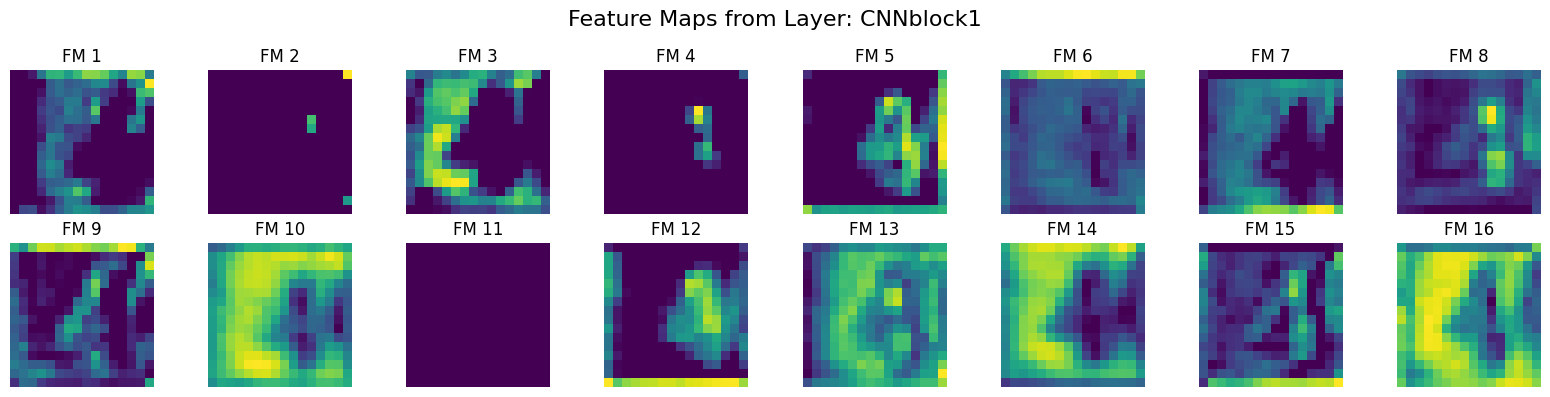

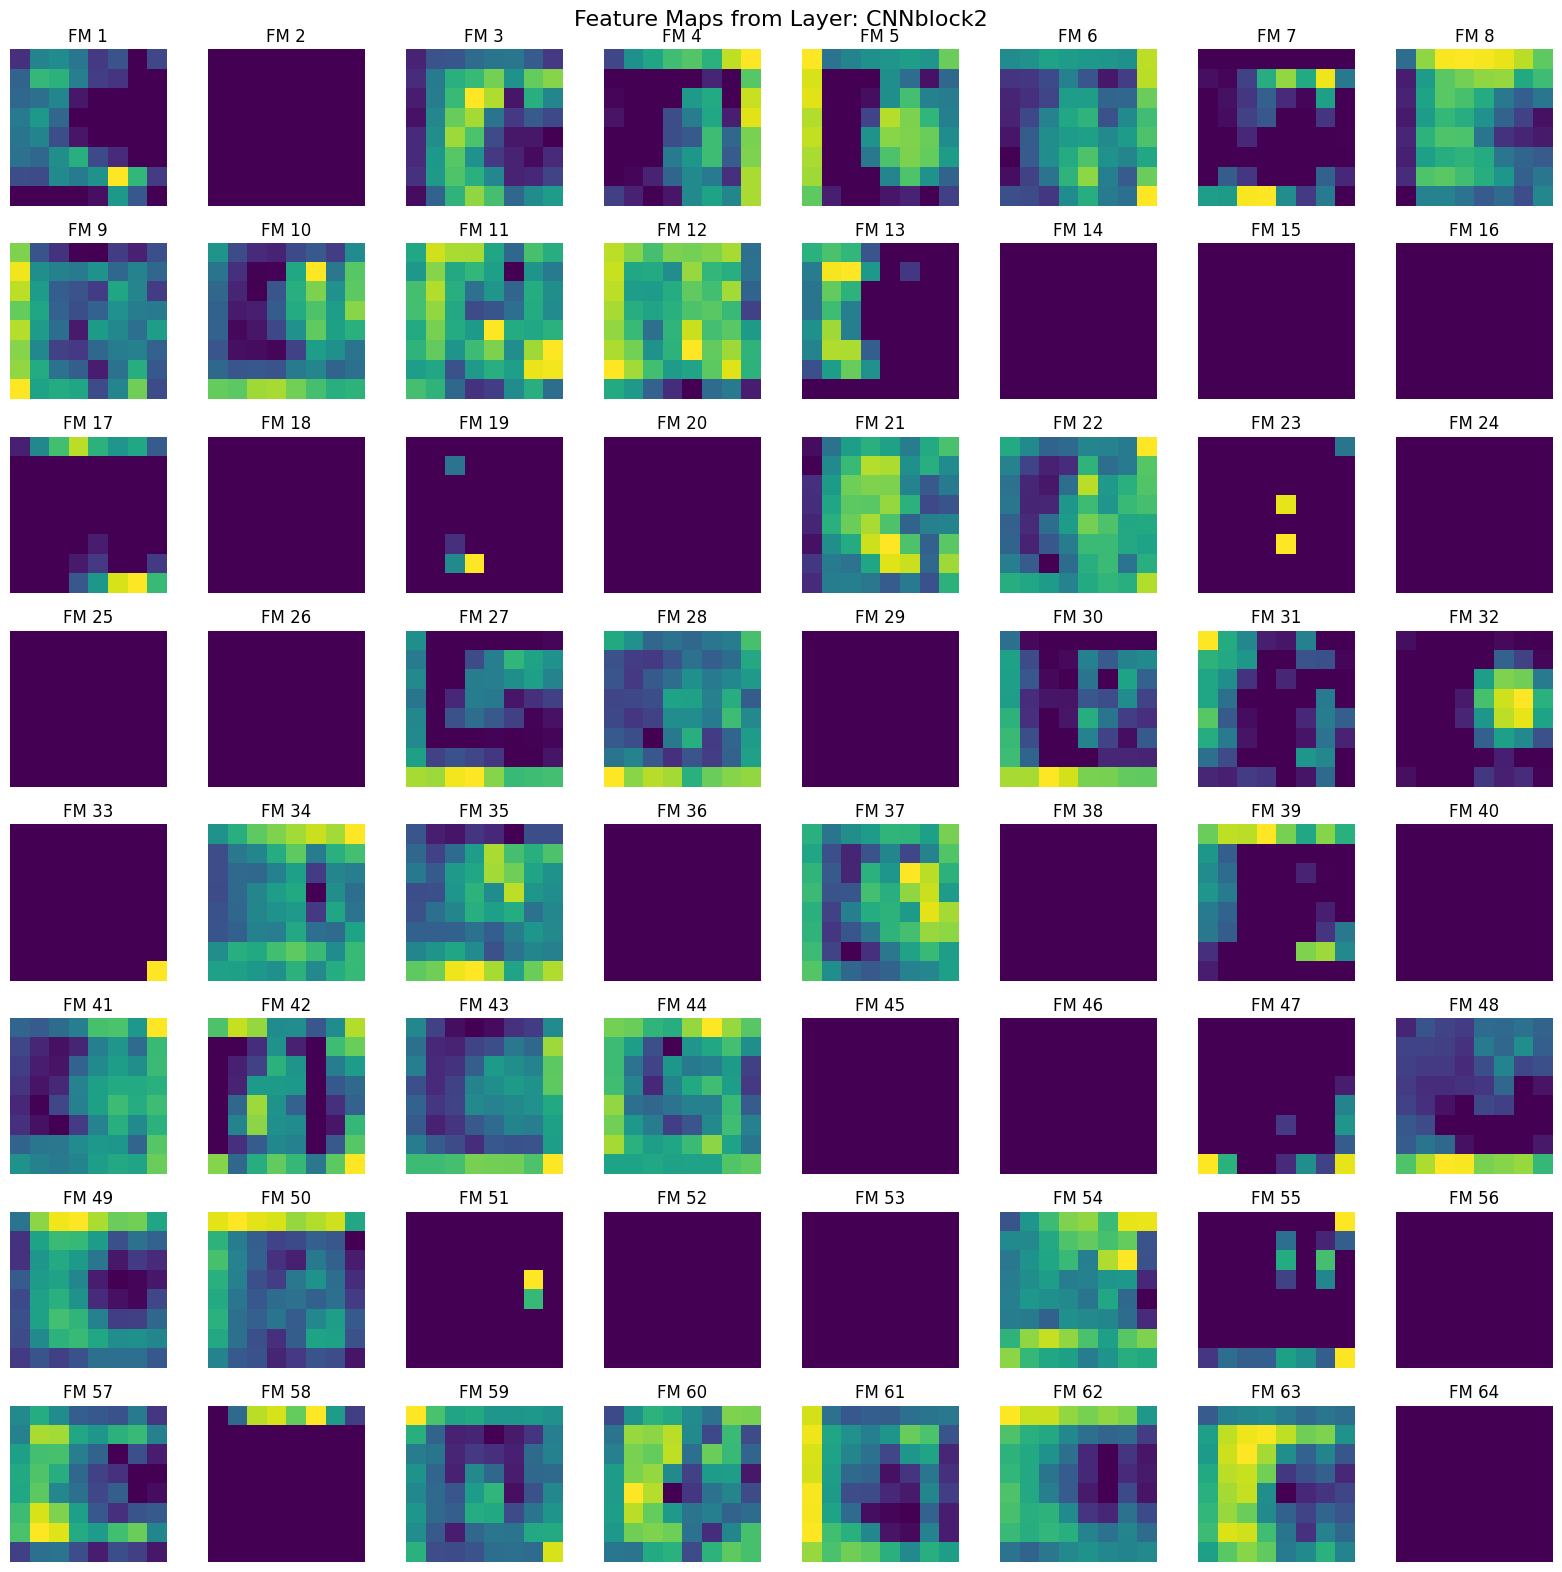

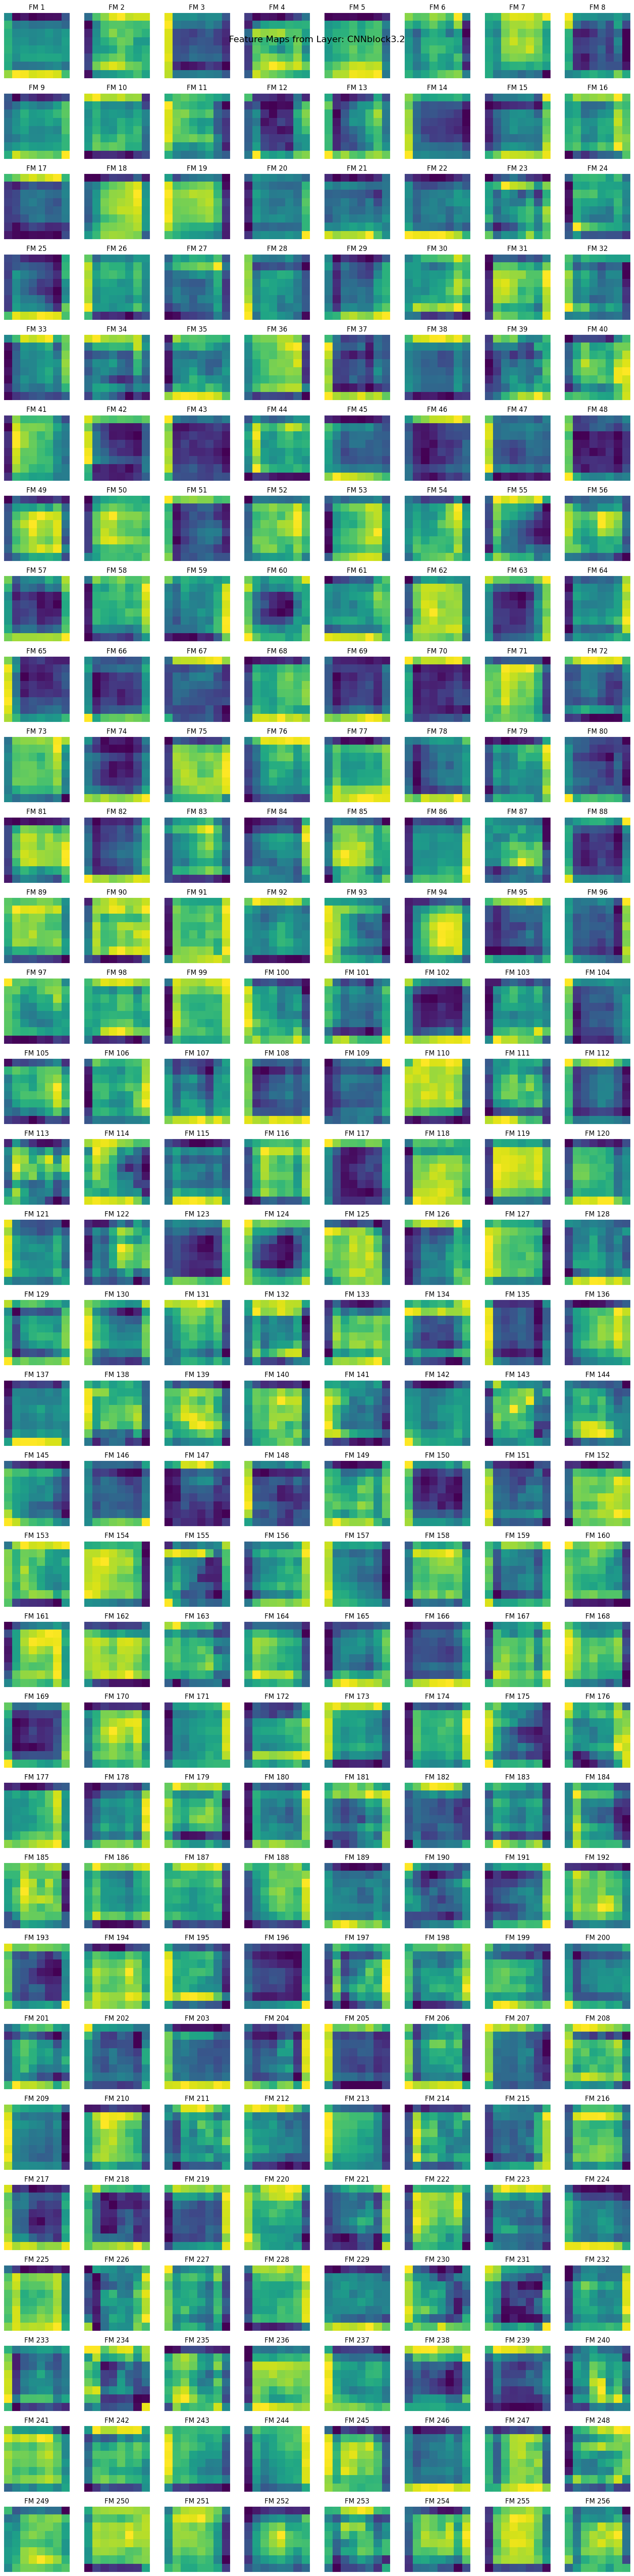

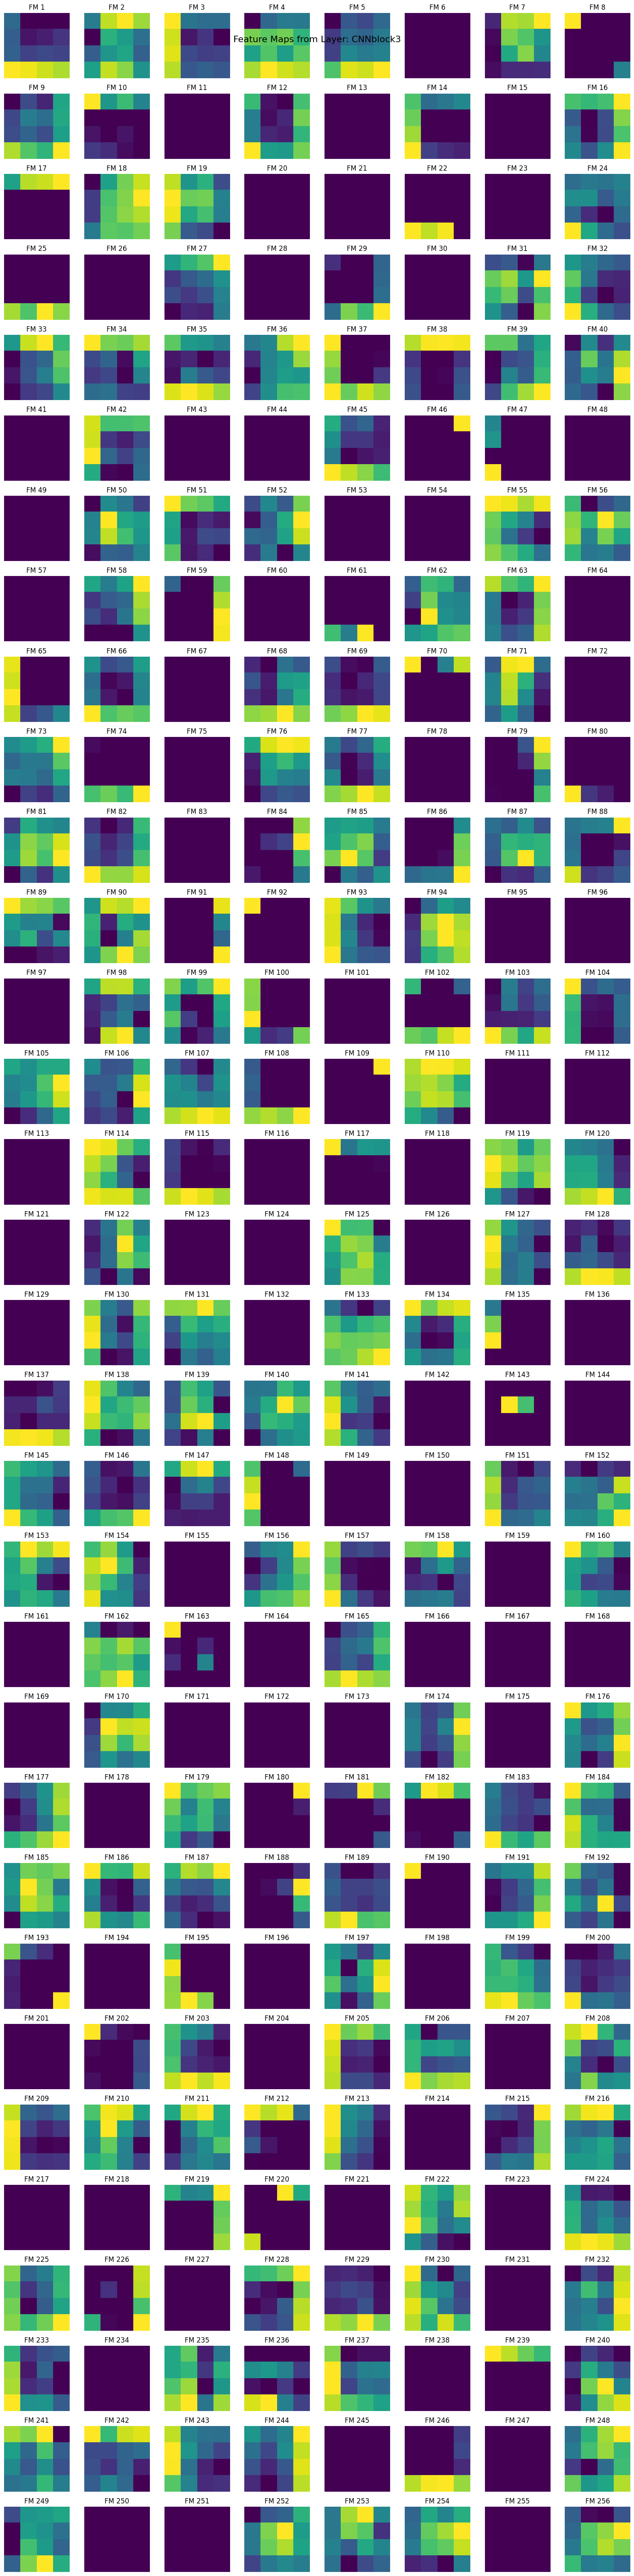

In [13]:
features = get_feature_maps(model, single_image, target_layer_names)

for layer_name, feature_map in features.items():
    print(f"Layer: {layer_name}, Feature Map Shape: {feature_map.shape}")

plot_feature_maps(features, target_layer_names)



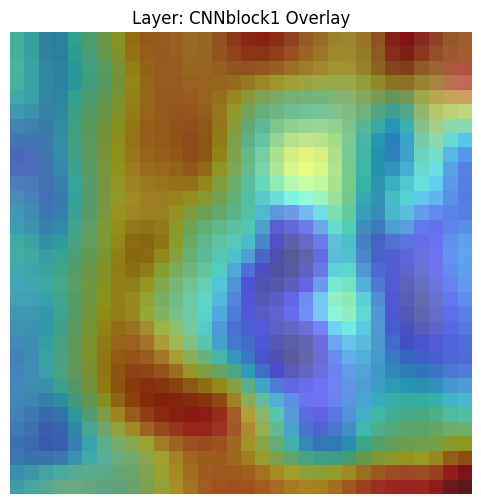

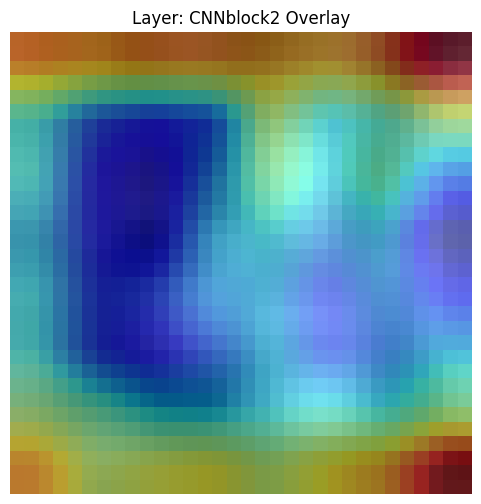

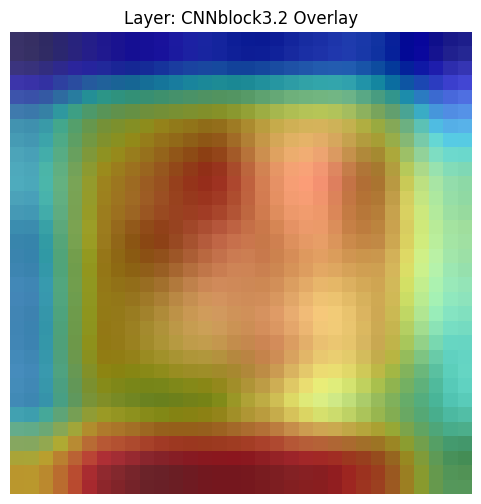

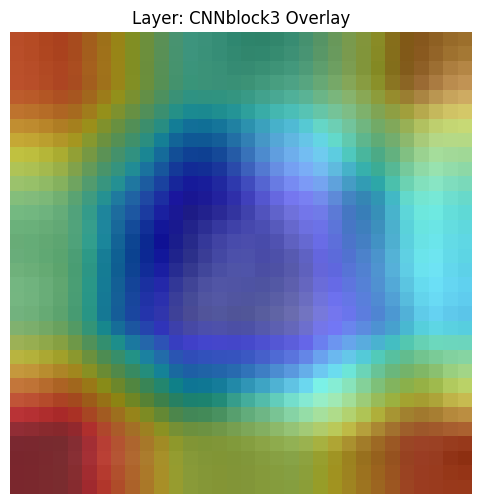

In [14]:
plot_feature_maps(features, target_layer_names, num_cols=8, overlay=True, input_image=single_image)